# Etapy budowy kampusów data center w USA
### Szereg czasowy Sentinel-2, 2018–2025, dwanaście obszarów

**Pytanie:** na jakim etapie budowy jest która inwestycja — i czy da się to
orzec z samych zdjęć satelitarnych, bez dostępu do dokumentacji budowy.

**Odpowiedź w jednym zdaniu:** da się rozpoznać *koniec* budowy (bryła
zamknięta) z dokładnością do pół roku, *początek* jest trudniejszy i zależy od
tego, czy teren był wcześniej polem uprawnym, a *rozbudowa dojrzałego kampusu*
jest w tym ujęciu niewidoczna.

In [1]:
%matplotlib inline
import json, os, warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, Markdown, display

import config as C, stages as S, viz, plot, narracja

plt.rcParams.update({"figure.dpi": 110, "savefig.bbox": "tight", "font.size": 9})
df  = pd.read_csv(os.path.join(C.OUT_DIR, "etapy.csv"))
dfl = pd.read_csv(os.path.join(C.OUT_DIR, "przebieg.csv"))
EPOCHS = sorted(dfl.epoch.unique())
GDZIE = {x["id"]: x.get("place", "?") for x in C.SITES}
KTORE = {x["id"]: x.get("control", False) for x in C.SITES}
print(f"{len(df)} obszarów · {len(EPOCHS)} epok półrocznych · {EPOCHS[0]}–{EPOCHS[-1]}")

12 obszarów · 16 epok półrocznych · 2018H1–2025H2


---
# 1 · Metoda

**Dane.** Sentinel-2 L2A z Microsoft Planetary Computer, kompozyty medianowe
półroczne (H1 = III–VIII, H2 = IX–II), 10 m, maskowanie chmur przez SCL.
Mediana z półrocza zamiast pojedynczej sceny, bo etap budowy zmienia się
w miesiącach, a chmury w dniach.

**Klasyfikacja.** Las losowy, pięć klas: ZIELEŃ / GRUNT / DACH / ASFALT / WODA.
Pola treningowe z danych publicznych — ESA WorldCover 10 m i obrysy z OSM —
pobierane z otoczenia kampusu **z wyłączeniem samego kampusu**.

**Dach i asfalt są osobno** i to jest sedno ostrożności: droga dojazdowa i plac
manewrowy powstają razem z wykopem, hala rok lub dwa później. Model, który ich
nie rozdziela, ogłasza „stoją budynki" na widok asfaltowego placu budowy.

**Zabudowa potwierdzona** — nie z jednej klasyfikacji, tylko po trzech filtrach,
z których żaden nie jest spektralny:
1. **pewność** `p(DACH) ≥ 0.60`
2. **spójność** skupisko ≥ 50 pikseli (0,5 ha)
3. **trwałość** klasa DACH w 3 kolejnych epokach, potem zapadka

Trzeci jest rozstrzygający: **jasna glina wysycha i moknie, budynek nie znika.**

**Pięć etapów:**

| etap | rozpoznany po |
|---|---|
| 0 PRZED BUDOWĄ | nie spełnia warunków etapu 1+ |
| 1 ROBOTY ZIEMNE | goły grunt podwyższony ponad **własny** poziom obszaru, utrzymany 3 epoki |
| 2 ZABUDOWA ROŚNIE | zabudowa potwierdzona ≥ 15% celu kampusu |
| 3 BRYŁA ZAMKNIĘTA | zabudowa potwierdzona ≥ 65% celu kampusu |
| 4 ZIELEŃ URZĄDZONA | bryła zamknięta + **powrót** zieleni w kołnierzu wokół hal |

---
# 2 · Skąd lista obszarów — z pomiaru, nie z pamięci

`discover.py` pobiera z OSM wszystkie obiekty `telecom=data_center` /
`building=data_center` w CONUS (**1730 hal**), skupia je w kampusy i wybiera
największe po powierzchni hal.

To jest ranking **mierzalny**, a nie ranking po nakładach — takiego nie da się
tu zweryfikować, więc go nie udaję.

Dwa obszary są **odniesieniem**: mają udokumentowaną oś czasu z doniesień
branżowych, więc można sprawdzić, czy wykryte daty zgadzają się z ogłoszonymi.

In [2]:
s = pd.DataFrame(json.load(open("sites.json", encoding="utf-8"))["sites"])
s["rola"] = s.get("control", False).fillna(False).map({True: "ODNIESIENIE", False: ""}) \
    if "control" in s.columns else ""
s["pow. hal [ha]"] = (s.hall_area_m2 / 1e4).round(0)
s["cel [%AOI]"] = (s.target_built_frac * 100).round(1)
display(s[["id", "place", "rola", "halls", "pow. hal [ha]", "cel [%AOI]"]]
        .rename(columns={"id": "obszar", "place": "gdzie", "halls": "hal"}))

,obszar,gdzie,rola,hal,pow. hal [ha],cel [%AOI]
0,amazon_web_services_3900,"Loudoun County, Virginia",,140,189.0,7.5
1,google_4006,"New Albany, Ohio",,17,45.0,3.6
2,quality_technology_services_3748,"Henrico County, Virginia",,17,43.0,3.6
3,bez_nazwy_3250,"Taylor County, Texas",,40,36.0,4.9
4,meta_4429,"Crook County, Oregon",,11,35.0,3.4
5,meta_4166,"Altoona, Iowa",,7,31.0,5.5
6,meta_4112,"Papillion, Nebraska",,9,31.0,2.0
7,meta_3482,"Valencia County, New Mexico",,5,29.0,9.5
8,stack_infrastructure_4555,"Hillsboro, Oregon",,20,28.0,1.9
9,google_4117,"Council Bluffs, Iowa",,16,27.0,4.3


---
# 3 · Wyniki — kto na jakim etapie

Wiersz = obszar, kolumna = epoka półroczna, kolor = etap. Przebieg jest
**niemalejący**: budowa się nie cofa, a bez tej zapadki jedna epoka z chmurami
wyrzucałaby obszar z etapu 3 na 1.

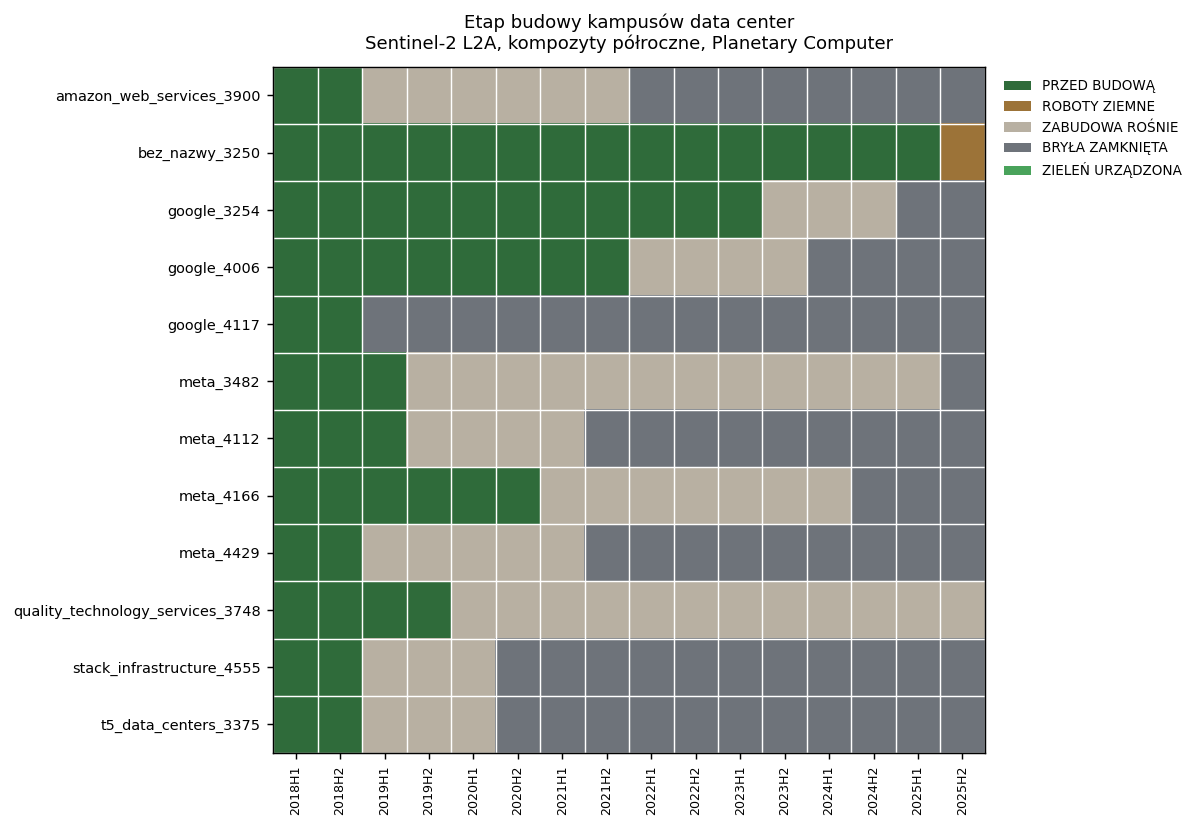

In [3]:
display(Image(os.path.join(C.OUT_DIR, "etapy.png")))

In [4]:
t = df.copy()
t["gdzie"] = t.id.map(GDZIE)
t["rola"] = t.id.map(lambda i: "ODNIESIENIE" if KTORE.get(i) else "")
t["etap"] = t.stage.map(S.STAGE_SHORT)
t["zabudowa [%]"] = (t.built_frac * 100).round(1)
t["cel_ef [%]"] = (t.target_built_frac * 100).round(1)
t["postęp [%]"] = (t.progress * 100).round(0)
display(t[["gdzie", "rola", "etap", "since", "zabudowa [%]", "cel_ef [%]",
           "postęp [%]"]].rename(columns={"since": "od"})
        .sort_values(["etap", "postęp [%]"], ascending=False))

,gdzie,rola,etap,od,zabudowa [%],cel_ef [%],postęp [%]
8,"Douglas County, Georgia",ODNIESIENIE,3/zamknięta,2020H2,14.1,2.5,570.0
9,"Hillsboro, Oregon",,3/zamknięta,2020H2,7.0,2.9,243.0
6,"Papillion, Nebraska",,3/zamknięta,2021H2,6.5,3.6,183.0
3,"Council Bluffs, Iowa",,3/zamknięta,2019H1,10.5,7.3,144.0
4,"Crook County, Oregon",,3/zamknięta,2021H2,6.5,4.9,133.0
2,"New Albany, Ohio",,3/zamknięta,2024H1,5.6,4.7,120.0
1,"Red Oak, Texas",ODNIESIENIE,3/zamknięta,2025H1,6.2,5.2,119.0
0,"Loudoun County, Virginia",,3/zamknięta,2022H1,5.3,5.6,94.0
7,"Altoona, Iowa",,3/zamknięta,2024H2,4.5,5.9,77.0
5,"Valencia County, New Mexico",,3/zamknięta,2025H2,5.7,8.7,65.0


**Jak to czytać — i czego tu nie ma.** Werdykt etapu jest wiarygodniejszy niż
liczba postępu. Mianownikiem postępu jest powierzchnia hal zmapowanych w OSM,
a kompletność OSM jest bardzo nierówna: postęp 570% znaczy „OSM zna ułamek
tego, co stoi", a nie „potok widzi pięć razy za dużo". Rozstrzyga to sekcja 7.

---
# 4 · Case study: Google Red Oak, Teksas

Najostrzejszy sprawdzian w całym zestawie, bo **cała budowa mieści się wewnątrz
szeregu** i ma publicznie znane daty.

In [5]:
display(Markdown(narracja.markdown("google_3254")))

### Google Red Oak, Ellis County, Teksas

*Building 1: ok. 287 500 sq ft, 107 MW, 165 akrów*

**Co mówią źródła:**

| data | zdarzenie | źródło |
|---|---|---|
| 2023-08-31 | ogłoszenie inwestycji: kampus za ~600 mln USD na działce ~375 akrów przy Ovilla Road | DCD / KERA |
| 2024-04 | planowany początek budowy | cleanview.co |
| 2025-12 | planowane zakończenie budowy | cleanview.co |
| 2025-09 | potwierdzenie, że obiekt jest operacyjny | WFAA |

**Co wykrył potok:**

| etap | oczekiwane ze źródeł | wykryte z Sentinela |
|---|---|---|
| ROBOTY ZIEMNE | 2024H1 (budowa od kwietnia 2024) | **2023H2** |
| ZABUDOWA ROŚNIE | 2024H2 - 2025H1 | **2023H2** |
| BRYŁA ZAMKNIĘTA | 2025H2 (operacyjny od 2025) | **2025H1** |
| ZIELEŃ URZĄDZONA | — | **nie wykryto** |

Stan na koniec szeregu: **BRYŁA ZAMKNIĘTA**, zabudowa potwierdzona 6.2% rdzenia przy celu 5.2% (postęp 119%).

**Jak wypadlo porownanie.** Koniec budowy potok trafia: BRYLA ZAMKNIETA od
2025H1 wobec obiektu operacyjnego od 2025 r. Poczatek wykrywa na 2023H2, czyli
POL ROKU PRZED oficjalnym startem budowy (kwiecien 2024) i tuz PO ogloszeniu
inwestycji (sierpien 2023) - co jest zgodne z przygotowaniem terenu, ale nalezy
to czytac jako "okolice przelomu 2023/2024", nie jako date dzienna.

**To ten obszar pokazal powazny blad.** W pierwszej wersji roboty ziemne
wychodzily na 2021H2 - dwa i pol roku za wczesnie. Przyczyna: AOI bylo polem
uprawnym, a udzial golej ziemi skakal sezonowo (2019H1 16,5% -> 2019H2 49,7%
-> 2021H1 19,3% -> 2021H2 54,9% -> 2022H1 61,2% -> 2022H2 27,1%). Zaorka daje
55-61% golej ziemi i WRACA do zieleni, czego warunek "przyrost ponad poziom
wyjsciowy" nie odrozniał od wykopu. Stad wymog utrzymania sie podwyzszonego
gruntu przez trzy epoki (`BARE_PERSISTENCE_EPOCHS`).

Źródła: [1](https://www.datacenterdynamics.com/en/news/google-announces-plans-for-red-oak-data-center-campus-in-texas/) · [2](https://www.keranews.org/science-technology/2023-09-01/google-is-growing-in-north-texas-with-new-data-center) · [3](https://cleanview.co/data-centers/texas/1602/red-oak---building-1) · [4](https://www.wfaa.com/article/money/business/google-40-billion-investment-in-texas-ellis-county/287-0bf6e355-b350-4c46-b706-6745e7cb7358)

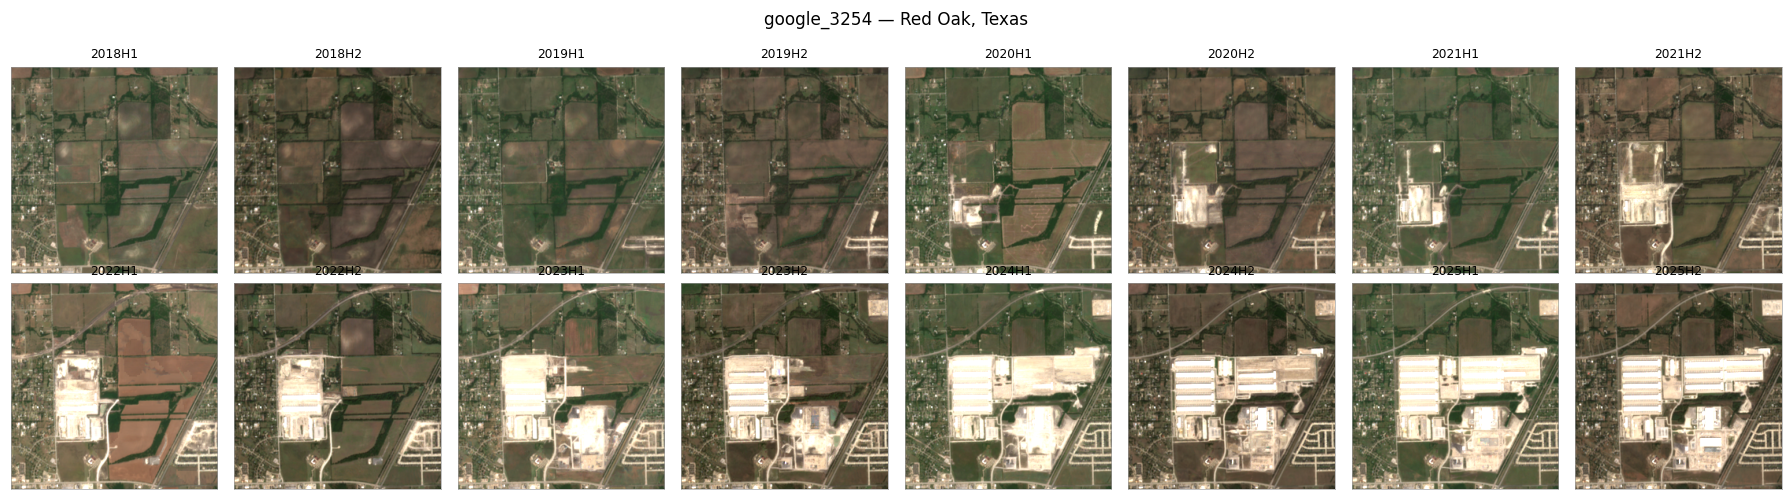

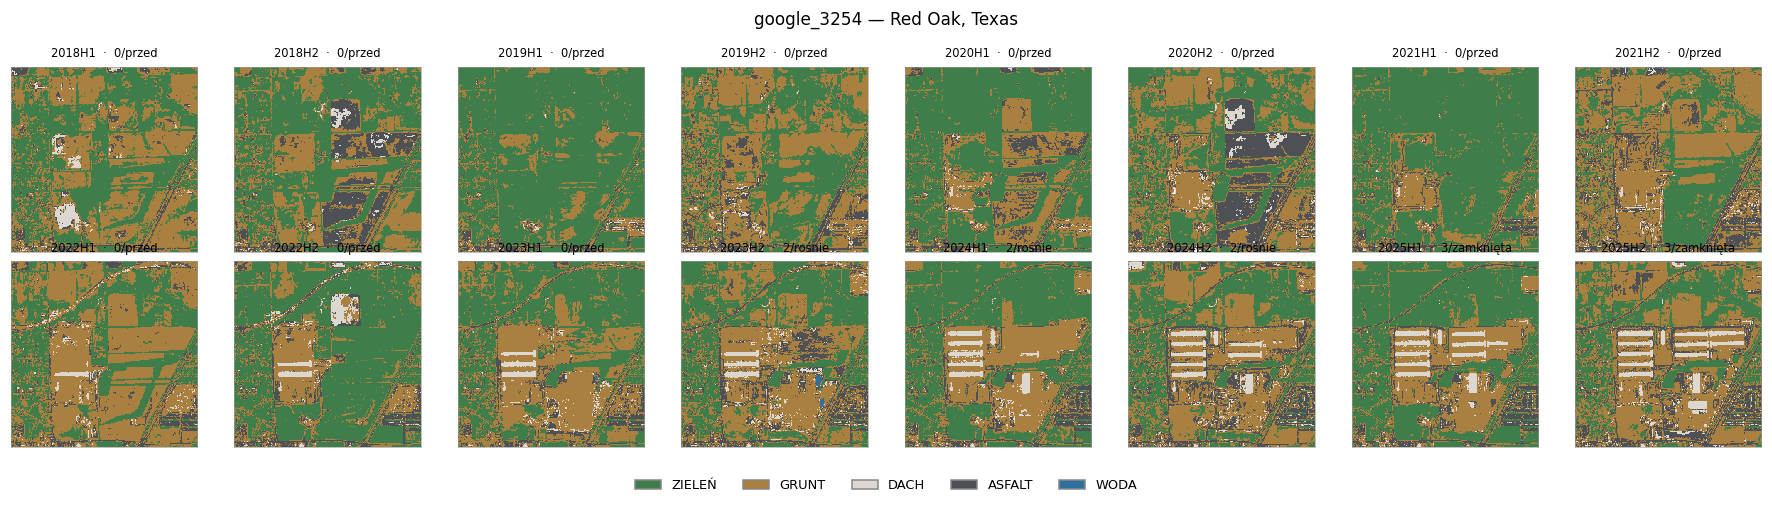

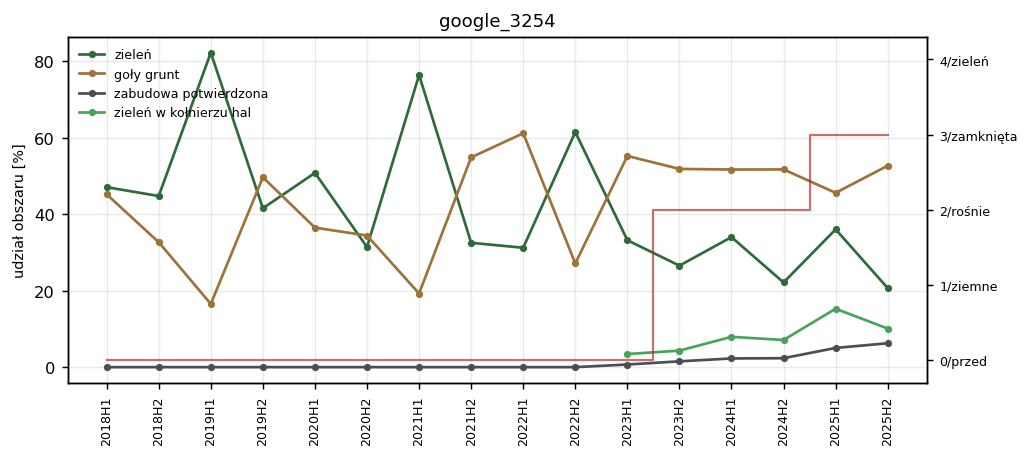

In [6]:
display(Image(os.path.join(C.OUT_DIR, "mozaiki",
                           "KONTROLNY_google_3254_1_barwy_naturalne.png")))
display(Image(os.path.join(C.OUT_DIR, "mozaiki",
                           "KONTROLNY_google_3254_3_klasyfikacja.png")))
display(Image(os.path.join(C.OUT_DIR, "krzywe", "google_3254.png")))

**To ten obszar wykrył poważny błąd.** W pierwszej wersji roboty ziemne
wychodziły na 2021H2 — dwa i pół roku przed faktycznym startem budowy.
Przyczyna widoczna w krzywej: AOI było **polem uprawnym**, a udział gołej ziemi
skakał sezonowo —

```
2019H1 16,5%  →  2019H2 49,7%  →  2021H1 19,3%  →  2021H2 54,9%  →  2022H1 61,2%  →  2022H2 27,1%
```

Zaorka daje 55–61% gołej ziemi i **wraca do zieleni**, czego warunek „przyrost
ponad poziom wyjściowy" nie odróżniał od wykopu. Stąd wymóg, by podwyższony
grunt utrzymał się przez trzy epoki.

---
# 5 · Case study: T5@Atlanta, Lithia Springs, Georgia

In [7]:
display(Markdown(narracja.markdown("t5_data_centers_3375")))

### T5@Atlanta, Lithia Springs, Douglas County, Georgia

*docelowo ok. 220 MW na ok. 80 akrach; T5@ATL III do 300 MW*

**Co mówią źródła:**

| data | zdarzenie | źródło |
|---|---|---|
| 2018 | początek zagospodarowania terenu przy 1456 Trae Lane | DCD |
| 2021 | zatwierdzenie wniosku dla obiektu 10-25 MW | interconnection.fyi |
| 2024-08 | początek budowy T5@Atlanta III (budynki 3-5, ok. 1,2 mln sq ft) | datacenterhawk |
| 2025-06 | zadaszenie (topping out) T5@ATL III | DCD |
| 2026-08 | planowane zakończenie T5@Atlanta III | datacenterhawk |

**Co wykrył potok:**

| etap | oczekiwane ze źródeł | wykryte z Sentinela |
|---|---|---|
| ROBOTY ZIEMNE | przed 2018 lub na początku szeregu - teren zagospodarowywany od 2018 | **2019H1** |
| ZABUDOWA ROŚNIE | w szeregu widoczna kolejna faza od 2024H2 | **2019H1** |
| BRYŁA ZAMKNIĘTA | część kampusu zamknięta wcześniej; III dopiero w budowie do 2026 | **2020H2** |
| ZIELEŃ URZĄDZONA | — | **nie wykryto** |

Stan na koniec szeregu: **BRYŁA ZAMKNIĘTA**, zabudowa potwierdzona 14.1% rdzenia przy celu 2.5% (postęp 570%).

**Jak wypadlo porownanie.** Potok widzi wczesna faze kampusu: roboty ziemne
i poczatek zabudowy w 2019H1, bryla zamknieta od 2020H2 - co odpowiada
budynkom oddanym na wczesnym etapie zagospodarowania terenu (od 2018).

**Czego NIE widzi: fazy z lat 2024-2026.** T5@Atlanta III ruszylo w sierpniu
2024 i ma sie skonczyc w sierpniu 2026, ale etap na wykresie stoi od 2020H2.
Powod jest wbudowany w konstrukcje: etapy sa NIEMALEJACE (zapadka), wiec raz
osiagnieta "bryla zamknieta" nie cofa sie i kolejna faza rozbudowy nie ma jak
sie pokazac jako zmiana etapu. Zapadka chroni przed migotaniem wyniku na
chmurach, ale kosztuje wlasnie to: ROZBUDOWA DOJRZALEGO KAMPUSU JEST NIEWIDOCZNA
w kolumnie etapu. Widac ja za to w krzywej udzialu zabudowy i na mapie
"kiedy pojawila sie zabudowa" - i tam nalezy jej szukac.

Źródła: [1](https://www.datacenterdynamics.com/en/news/t5-and-corscale-top-out-data-centers-in-georgia-and-virginia/) · [2](https://datacenterhawk.com/marketplace/providers/t5-data-centers/trae-lane/t5-atlanta-bldg-2) · [3](https://baxtel.com/data-center/t5-atlanta-iii-campus) · [4](https://www.interconnection.fyi/data-center/project/t5-data-centers-bb0cf2bf)

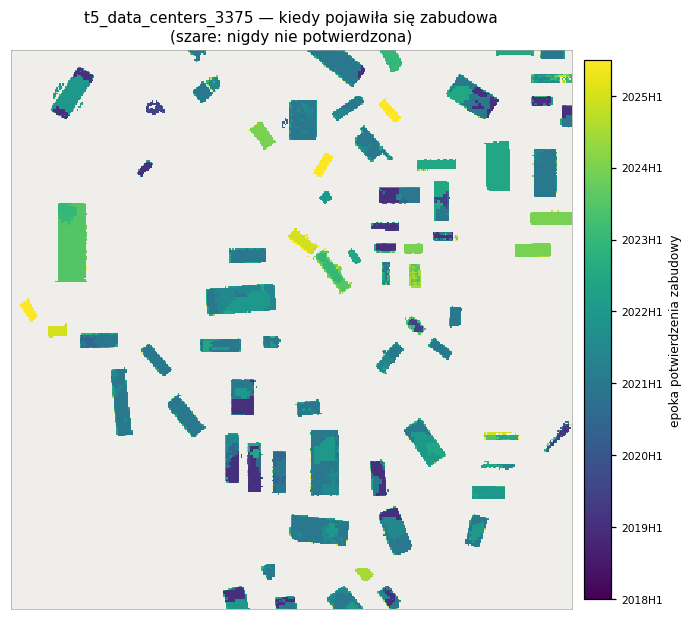

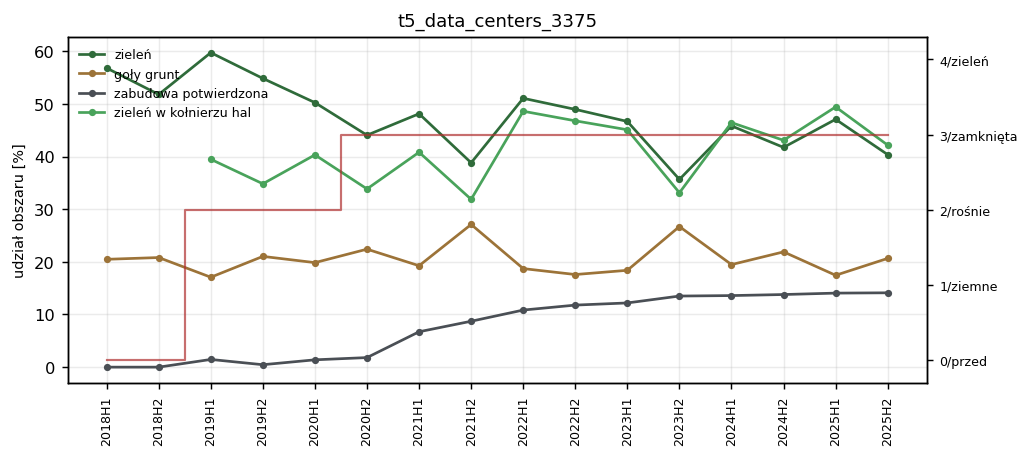

In [8]:
display(Image(os.path.join(C.OUT_DIR, "mozaiki",
                           "KONTROLNY_t5_data_centers_3375_4_wzrost_zabudowy.png")))
display(Image(os.path.join(C.OUT_DIR, "krzywe", "t5_data_centers_3375.png")))

**Ograniczenie konstrukcyjne, nie usterka.** Faza T5@ATL III (start VIII 2024,
zadaszenie VI 2025) nie pokazuje się w kolumnie etapu, bo etapy są niemalejące
i „bryła zamknięta" z 2020H2 już się nie cofnie. Rozbudowy dojrzałego kampusu
trzeba szukać w **krzywej udziału zabudowy** i na **mapie „kiedy pojawiła się
zabudowa"** — obie powyżej.

---
# 6 · Case study: Taylor County, Teksas — cena poprawki

Półpustynia: poziom wyjściowy to **58% gołej ziemi**. Sygnał budowy jest tu
czysty i monotoniczny (73,5% → 84,1% → 87,1%), więc wymóg trzech epok
**opóźnił wykrycie z 2024H2 na 2025H2 — o rok**.

To jest świadomy wybór: wariant, który nie wymyśla budowy tam, gdzie jej nie ma,
kosztem spóźnienia tam, gdzie sygnał jest czysty. W tym zadaniu fałszywe
ogłoszenie etapu jest gorsze niż spóźnienie.

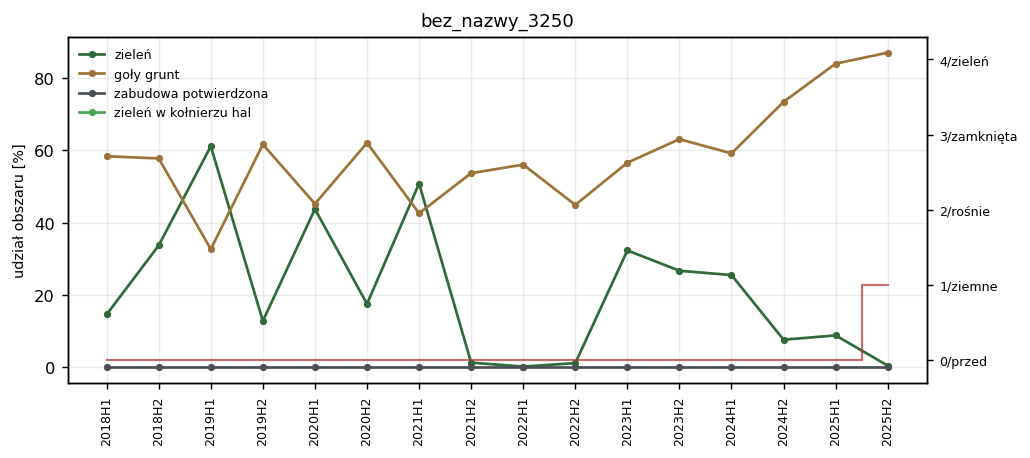

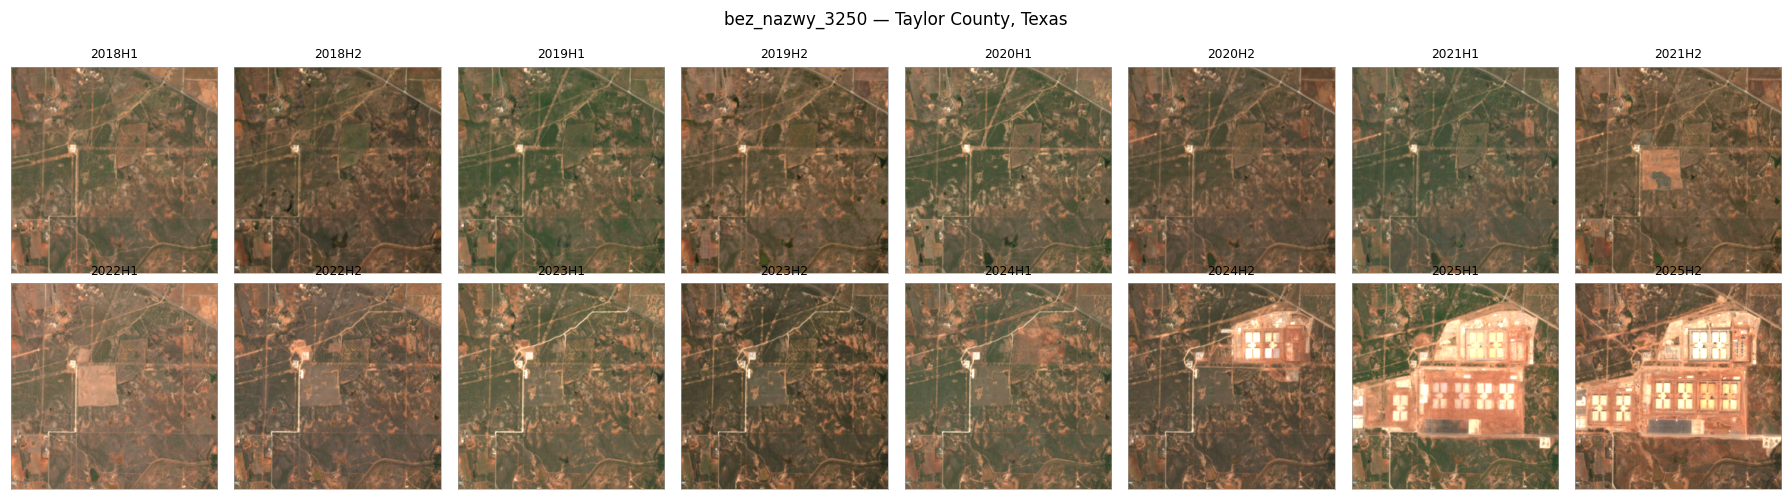

In [9]:
display(Image(os.path.join(C.OUT_DIR, "krzywe", "bez_nazwy_3250.png")))
display(Image(os.path.join(C.OUT_DIR, "mozaiki",
                           "bez_nazwy_3250_1_barwy_naturalne.png")))

---
# 7 · Ile to jest warte

Dwie niezależne miary: jakość klasyfikatora na danych sprawdzających
i zgodność „zabudowy potwierdzonej" z obrysami budynków OSM, których model
dla tych obszarów nie widział.

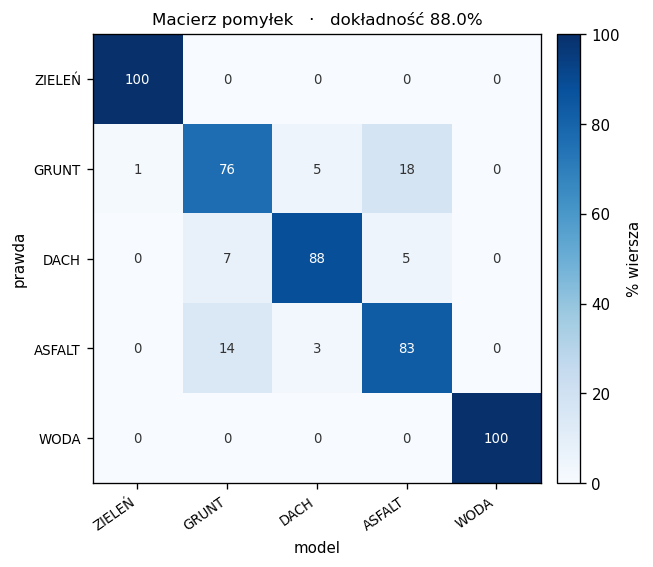

GRUNT wzięty za DACH: 4.8%  — i to jest błąd, który filtry czasowe mają dociąć


In [10]:
import joblib
rep = joblib.load(os.path.join(C.OUT_DIR, "model.joblib"))["report"]
viz.confusion(rep); plt.show()
print(f"GRUNT wzięty za DACH: {rep.get('bare_as_roof', float('nan'))*100:.1f}%"
      "  — i to jest błąd, który filtry czasowe mają dociąć")

Zieleń i woda rozdzielają się bezbłędnie; **cała pomyłka siedzi między gruntem,
dachem i asfaltem** i jest nieusuwalna spektralnie — świeży beton, blacha
i przesuszona jasna glina mają w sześciu pasmach Sentinela podpisy, które na
siebie zachodzą.

Kalibracja progów (`calibrate.py`, 30 kombinacji na zapisanych mapach
prawdopodobieństwa) — średnia po obszarach:

| progi | celność | pokrycie |
|---|---|---|
| 0.60 / 25 px / trwałość 2 | 65% | 74% |
| **0.60 / 50 px / trwałość 3** ← wybrane | **74%** | 67% |
| 0.90 / 50 px / trwałość 3 | 78% | 35% |

Podniesienie progu do 0,90 kupuje jeszcze 4 punkty celności, a kosztuje połowę
pokrycia — dlatego nie.

---
# 8 · Wnioski

**Co działa.**
* **Koniec budowy** — „bryła zamknięta" wypada z dokładnością do pół roku
  (Red Oak: wykryte 2025H1 wobec obiektu operacyjnego od 2025).
* **Rozdzielenie dachu od asfaltu** — bez niego plac manewrowy ogłaszałby halę
  rok za wcześnie.
* **Trwałość zamiast spektrum** — najważniejsze rozstrzygnięcia nie są
  spektralne, tylko czasowe. Jasna glina wysycha i moknie, budynek nie znika.

**Co nie działa albo działa gorzej.**
* **Początek budowy na gruntach rolnych** — zaorka wygląda jak wykop. Wymóg
  trzech epok to łata, nie rozwiązanie; właściwe byłoby porównanie do poziomu
  z tego samego sezonu.
* **Rozbudowa dojrzałego kampusu** — zapadka etapów ją ukrywa. Widać ją tylko
  w krzywych i na mapie wzrostu zabudowy.
* **Postęp jako liczba** — mianownik (powierzchnia hal w OSM) ma nierówną
  kompletność, więc rozrzut 0–570% mówi więcej o OSM niż o budowach.

**Czego ta analiza nie mówi.**
* To **nie jest ranking po nakładach**, tylko po powierzchni hal zmapowanych
  w OSM. Kampus niezmapowany nie istnieje w tym zestawieniu.
* Daty z doniesień branżowych mówią, kiedy coś **ogłoszono i planowano** — nie
  kiedy wjechały koparki. Dlatego zgodność oceniam w epokach półrocznych.
* Zapadka zakłada, że hal się nie rozbiera.

**Gdyby to ciągnąć dalej**, w tej kolejności: poziom wyjściowy gruntu liczony
osobno dla H1 i H2 (usuwa sezonowość rolną u źródła), etap „rozbudowa" obok
niemalejącej skali, i cel zabudowy z obrysów innych niż OSM, żeby postęp
przestał zależeć od kompletności jednego źródła.